In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display first five records
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Number of Rows: 7043
Number of Columns: 21


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [9]:
# Create a copy of the original dataset
df_clean = df.copy()

# Drop unnecessary column
df_clean.drop('customerID', axis=1, inplace=True)

print("Dataset shape:", df_clean.shape)

Dataset shape: (7043, 20)


In [10]:
# Convert TotalCharges into numeric format
df_clean['TotalCharges'] = pd.to_numeric(
    df_clean['TotalCharges'],
    errors='coerce'
)

# Check missing values
df_clean['TotalCharges'].isnull().sum()

np.int64(11)

In [11]:
# Display rows with missing TotalCharges
df_clean[df_clean['TotalCharges'].isnull()]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [12]:
# Replace missing TotalCharges with 0
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

In [13]:
print("Duplicate records:", df_clean.duplicated().sum())

Duplicate records: 22


In [14]:
# Numerical columns
numerical_features = df_clean.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Categorical columns
categorical_features = df_clean.select_dtypes(
    include=['object']
).columns.tolist()

# Remove target from input feature lists
categorical_features.remove('Churn')

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [15]:
# Independent variables
X = df_clean.drop('Churn', axis=1)

# Dependent variable
y = df_clean['Churn']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


### Data Preparation Summary

- Loaded the IBM Telco Customer Churn dataset (7,043 rows, 21 columns).
- Inspected dataset structure, data types and missing values.
- Removed the unnecessary `customerID` column.
- Converted `TotalCharges` from object to numeric.
- Handled 11 missing values in `TotalCharges`.
- Identified 4 numerical and 15 categorical features.
- Separated independent variables (X) and target variable (y).
- Target variable: `Churn`.

## 4. Exploratory Data Analysis (EDA)

EDA is performed to understand customer behaviour, identify patterns and discover relationships between customer features and churn.

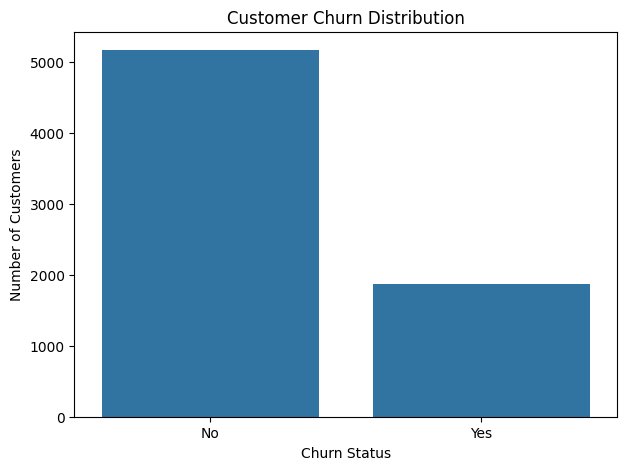

In [16]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.show()

In [17]:
churn_percentage = df_clean['Churn'].value_counts(normalize=True) * 100

print(churn_percentage.round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


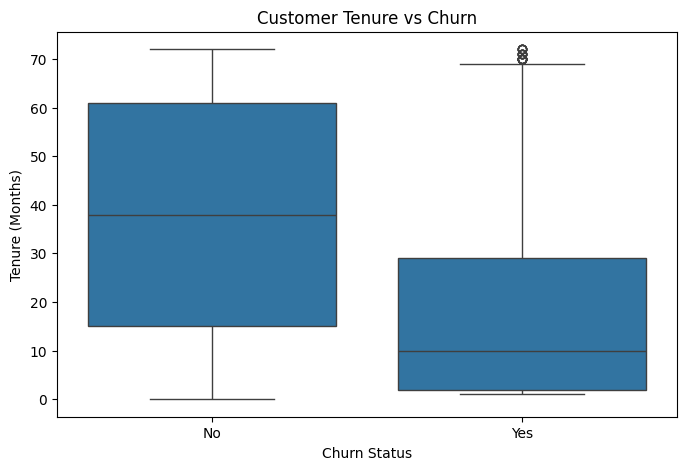

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x='Churn', y='tenure')

plt.title('Customer Tenure vs Churn')
plt.xlabel('Churn Status')
plt.ylabel('Tenure (Months)')

plt.show()

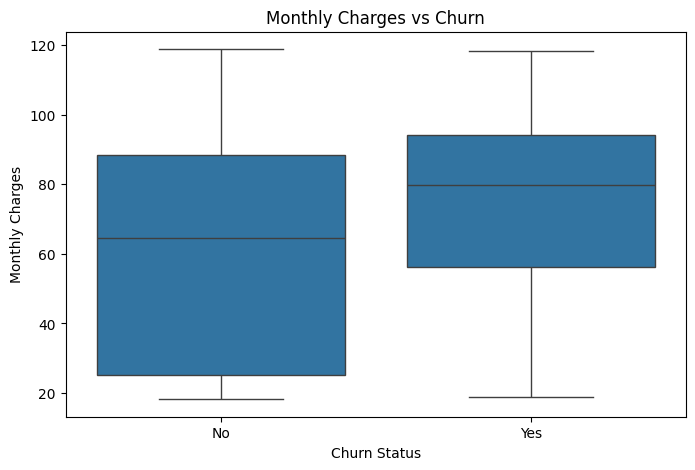

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x='Churn', y='MonthlyCharges')

plt.title('Monthly Charges vs Churn')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')

plt.show()

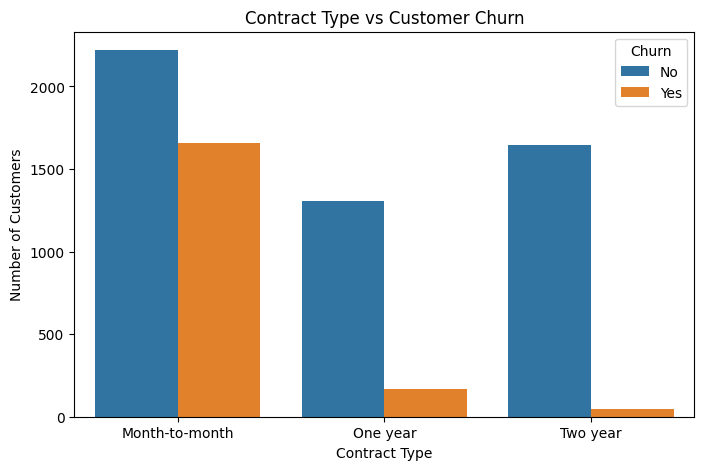

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x='Contract', hue='Churn')

plt.title('Contract Type vs Customer Churn')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

In [21]:
contract_churn = pd.crosstab(
    df_clean['Contract'],
    df_clean['Churn'],
    normalize='index'
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


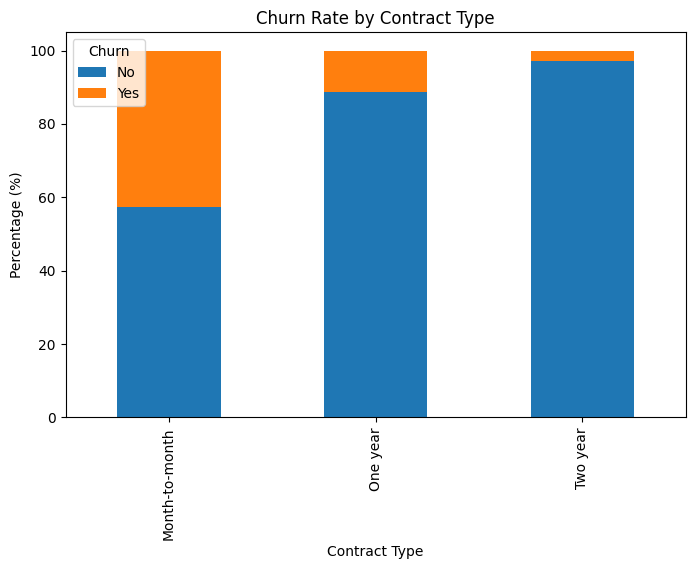

In [22]:
contract_churn.plot(kind='bar', stacked=True, figsize=(8, 5))

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Percentage (%)')
plt.legend(title='Churn')

plt.show()

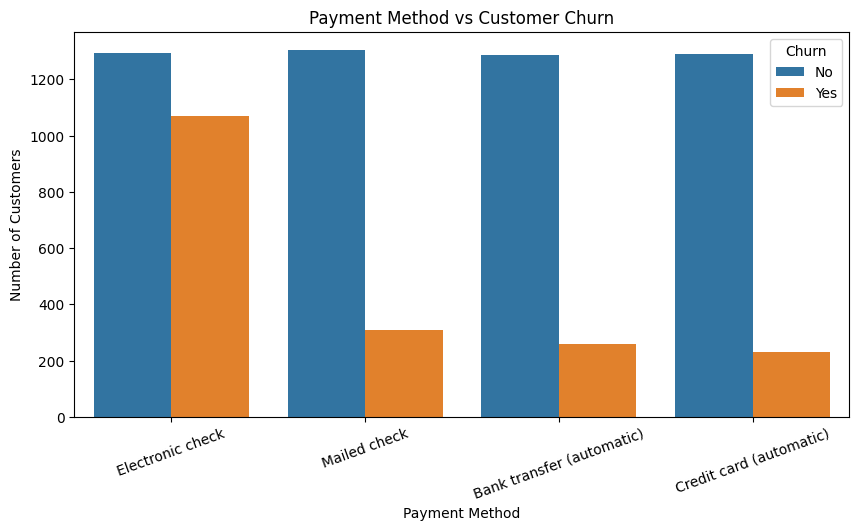

In [23]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df_clean, x='PaymentMethod', hue='Churn')

plt.title('Payment Method vs Customer Churn')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20)

plt.show()

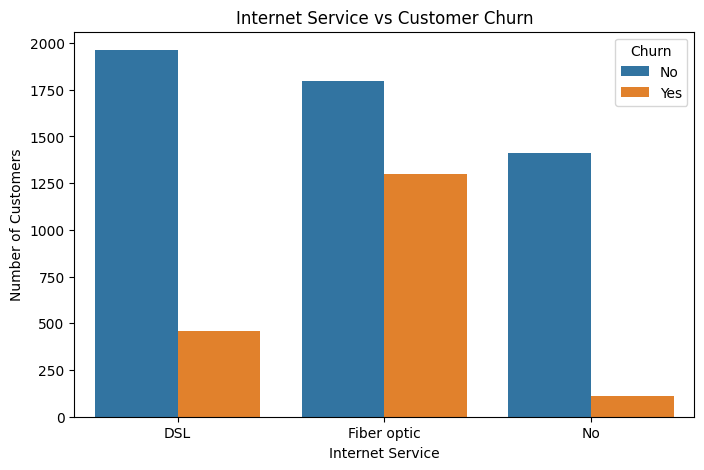

In [24]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x='InternetService', hue='Churn')

plt.title('Internet Service vs Customer Churn')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')

plt.show()

### EDA Summary

1. Churn Distribution: Approximately 26.54% of customers have churned.
2. Tenure: Customers with shorter tenure show higher churn.
3. Monthly Charges: Churned customers generally pay higher monthly charges.
4. Contract: Month-to-month customers show higher churn.
5. Payment Method: Electronic check users show higher churn.
6. Internet Service: Fiber optic customers show higher churn.

These observations help identify customer characteristics associated with churn and guide the upcoming Machine Learning process.

In [25]:
from sklearn.model_selection import train_test_split

# Convert target into binary values
y = y.map({'No': 0, 'Yes': 1})

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5634, 19)
Testing Data: (1409, 19)


In [26]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [27]:
print(X_train.shape)
print(X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(5634, 19)
(1409, 19)
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


## 6. Model Training

Train multiple Machine Learning classification algorithms using the prepared dataset to identify the best-performing customer churn prediction model.

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Logistic Regression
lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

# Random Forest
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

# XGBoost
xgb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        random_state=42,
        eval_metric='logloss'
    ))
])

print("All model pipelines created successfully!")

All model pipelines created successfully!


In [29]:
# Train Logistic Regression
lr_model.fit(X_train, y_train)

# Train Random Forest
rf_model.fit(X_train, y_train)

# Train XGBoost
xgb_model.fit(X_train, y_train)

print("All models trained successfully!")

All models trained successfully!


## 7. Model Evaluation

Evaluate the trained classification models using multiple performance metrics to identify the most suitable model for customer churn prediction.

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

models = {
    'Logistic Regression': lr_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.738112,0.504303,0.783422,0.613613,0.841639
1,Random Forest,0.782825,0.618881,0.473262,0.536364,0.823214
2,XGBoost,0.805536,0.670068,0.526738,0.589820,0.843755


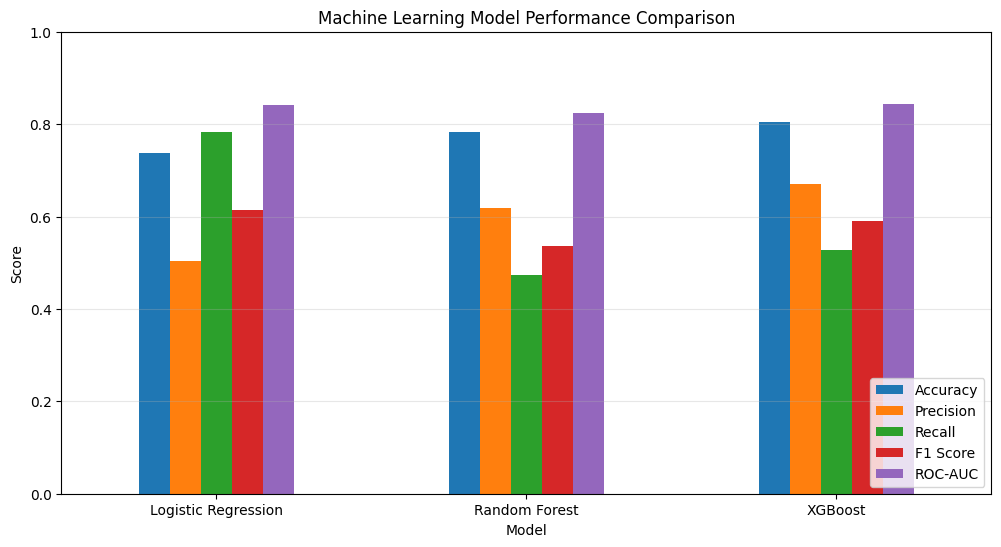

In [31]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

results_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)

plt.show()

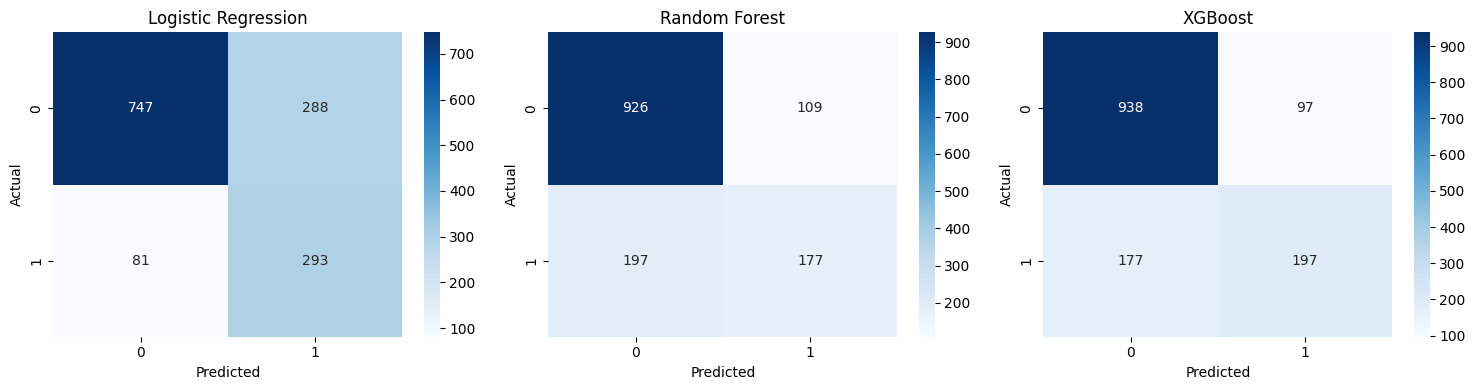

In [32]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

## 8. Feature Importance Analysis

Identify the most influential customer features affecting churn predictions using permutation importance.

In [33]:
from sklearn.inspection import permutation_importance

# Calculate feature importance
importance = permutation_importance(
    lr_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='roc_auc'
)

# Create importance dataframe
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance.importances_mean
})

# Sort features
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_df

,Feature,Importance
4,tenure,0.156136
7,InternetService,0.042538
17,MonthlyCharges,0.039888
14,Contract,0.039411
18,TotalCharges,0.012147
13,StreamingMovies,0.004555
8,OnlineSecurity,0.004259
12,StreamingTV,0.004014
11,TechSupport,0.003644
16,PaymentMethod,0.003359


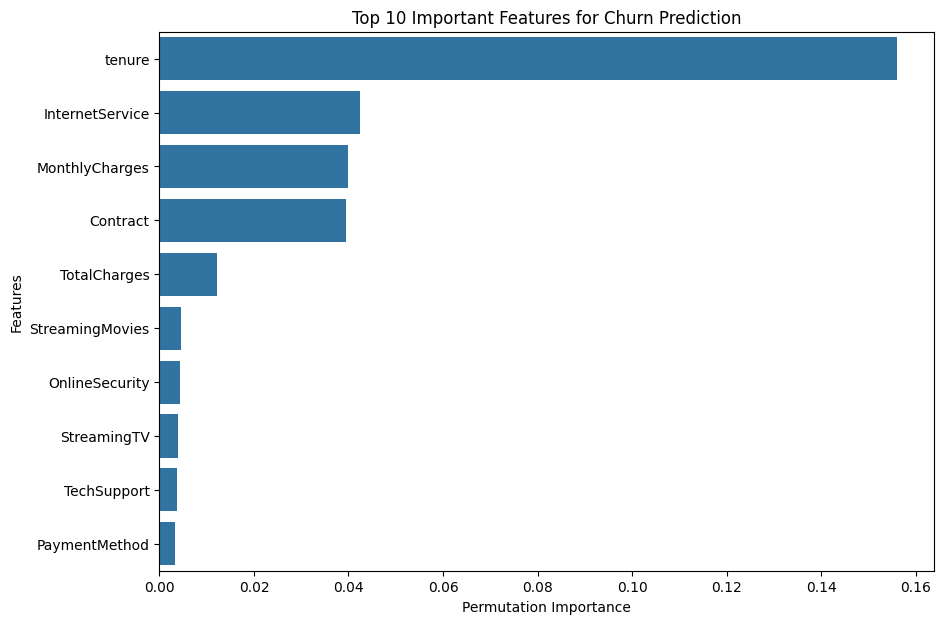

In [34]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features for Churn Prediction')
plt.xlabel('Permutation Importance')
plt.ylabel('Features')

plt.show()

## 9. Model Saving

Save the selected Machine Learning model and preprocessing pipeline using Joblib for future predictions and application integration.

In [35]:
import joblib
import os

# Create models directory
os.makedirs('models', exist_ok=True)

# Save complete model pipeline
joblib.dump(
    lr_model,
    'models/customer_churn_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [36]:
loaded_model = joblib.load(
    'models/customer_churn_model.pkl'
)

print("Model loaded successfully!")

Model loaded successfully!


In [37]:
sample_customer = X_test.iloc[[0]]

prediction = loaded_model.predict(sample_customer)

probability = loaded_model.predict_proba(sample_customer)

print("Prediction:", "Churn" if prediction[0] == 1 else "No Churn")
print("Churn Probability:", round(probability[0][1] * 100, 2), "%")

Prediction: No Churn
Churn Probability: 11.77 %
